# T-RAG · Notebook 4J — An independent LLM sentiment judge (GPU, teammate's account)

## About this notebook

**What it does :** In Notebooks 2 and 4, FinBERT labels every article and tweet. The correct answers to the sentiment questions are then computed from those same labels, which someone could fairly call circular. This notebook adds a **second, independent labeller**. For every one of the 107,509 news articles and tweets, Qwen2.5-7B-Instruct is asked: "For an investor in Tesla (or the article's company), is this text positive, negative or neutral?" The model does not write an answer. Instead, we read the probability it gives to each of the three words and take the highest. This is fast, gives the same result every time, and comes with a confidence score.

It then compares the two labellers. On single documents they agree 57% of the time on news (Cohen's κ 0.31) and 44% on tweets. But their monthly timelines move together closely: for news, the correlation is 0.64–0.95 across companies. So the sentiment timelines do not depend on which labeller is used. The labels are saved and used in Notebooks 5 and 6 as a **second answer key** for every sentiment question.

**Needs :** Notebook 2's output and the tweets dataset. GPU T4 ×2, about 5 hours.

**Produces :** `trag_judge/` with `llm_labels.parquet`, agreement and confusion tables, and a figure comparing the monthly timelines.

In [1]:
# ============================ CONFIG ============================
from pathlib import Path

JUDGE_MODEL = "Qwen/Qwen2.5-7B-Instruct"   # or "kaggle:llama-3.1/transformers/8b-instruct" (attach it under Models)
FINBERT_MODEL = "ProsusAI/finbert"          # only for tweets (news already has FinBERT labels from Notebook 2)
START, END = "2021-01-01", "2023-12-31"
NEWS_CHARS, TWEET_CHARS = 500, 300          # text shown to the judge
TOKENS_PER_BATCH = 8192                     # padded tokens per forward pass (halved automatically on out-of-memory)
BLOCK = 4096                                # documents per checkpoint
MAX_HOURS = 8.0                             # stop labelling after this; everything done so far is kept
SEED = 7

ON_KAGGLE = Path("/kaggle/working").exists()
OUT = Path("/kaggle/working/trag_judge") if ON_KAGGLE else Path("trag_judge")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT.resolve())

Output folder: /kaggle/working/trag_judge


In [2]:
!pip install -q accelerate

In [3]:
import re, json, time, glob, warnings, traceback
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, f1_score, accuracy_score, confusion_matrix
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 100)
N_GPU = torch.cuda.device_count()
DEV0 = "cuda:0" if N_GPU else "cpu"
print("torch", torch.__version__, "| GPUs:", N_GPU)
SUMMARY, T0 = {"judge": JUDGE_MODEL}, time.time()
LABELS = ["positive", "negative", "neutral"]

TICKERS = ["TSLA", "AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "NFLX", "AMD", "INTC"]
COMPANY = {"TSLA": "Tesla", "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "Nvidia", "AMZN": "Amazon",
           "META": "Meta", "GOOGL": "Alphabet", "NFLX": "Netflix", "AMD": "AMD", "INTC": "Intel", "ALL": "the market"}

torch 2.11.0+cu130 | GPUs: 2


## Step 1 — Load the documents: news (Notebook 2) and tweets

The tweets are loaded and cleaned with **exactly the same code as Notebook 4**, so each tweet has the same ID in both notebooks. FinBERT labels the tweets here too, so FinBERT and the judge can be compared on social media.

In [4]:
def find_input(name, folder="trag_index"):
    hits = sorted(glob.glob(f"/kaggle/input/**/{folder}/{name}", recursive=True)) + sorted(glob.glob(f"{folder}/{name}"))
    return hits[0] if hits else None

p = find_input("chunks.parquet")
if p is None:
    raise FileNotFoundError("trag_index/chunks.parquet not found — attach Notebook 2's output.")
news = pd.read_parquet(p)
news = pd.DataFrame({"doc_id": news.doc_id, "source": "news", "ticker": news.ticker, "tickers_mentioned": news.tickers_mentioned,
                     "day0": pd.to_datetime(news.day0), "text": news.text_for_scoring.astype(str).str.slice(0, NEWS_CHARS),
                     "fin_label": news.label, "fin_score": news.score})
print(f"news: {len(news):,}", news.ticker.value_counts().to_dict())

import hashlib
TWEET_MAP = {"TSLA": "TSLA", "AAPL": "AAPL", "MSFT": "MSFT", "NVDA": "NVDA", "AMZN": "AMZN", "META": "META",
             "FB": "META", "GOOG": "GOOGL", "GOOGL": "GOOGL", "NFLX": "NFLX", "AMD": "AMD", "INTC": "INTC"}

def find_tweets_csv():
    hits = sorted(glob.glob("/kaggle/input/**/stock_tweets.csv", recursive=True)) + sorted(glob.glob("stock_tweets.csv"))
    if not hits:
        hits = [f for f in sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True)) if "tweet" in Path(f).name.lower()]
    return hits[0] if hits else None

def tweet_id(t, raw_date, raw_text):
    return "tw_" + hashlib.md5(f"{t}|{raw_date}|{raw_text}".encode("utf-8", "ignore")).hexdigest()[:12]

def load_tweets(path, start="2021-01-01", end="2023-12-31"):
    raw = pd.read_csv(path, dtype=str, on_bad_lines="skip")
    cols = {c.strip().lower(): c for c in raw.columns}
    pick = lambda *names: next((cols[n] for n in names if n in cols), None)
    dc = pick("date", "datetime", "created_at") or next(c for k, c in cols.items() if "date" in k)
    xc = pick("tweet", "text", "content") or next(c for k, c in cols.items() if "tweet" in k or "text" in k)
    sc = pick("stock name", "stock_name", "ticker", "symbol") or next(c for k, c in cols.items() if "stock" in k or "ticker" in k)
    print("Tweet columns used:", {"date": dc, "text": xc, "ticker": sc}, "| rows:", len(raw))
    d = pd.DataFrame({"raw_date": raw[dc].astype(str), "raw_text": raw[xc].fillna("").astype(str),
                      "sym": raw[sc].fillna("").astype(str).str.upper().str.strip()})
    d["ticker"] = d.sym.map(TWEET_MAP)
    d = d[d.ticker.notna()].copy()
    d["published_at"] = pd.to_datetime(d.raw_date, utc=True, errors="coerce", format="mixed")
    d = d[d.published_at.notna()]
    d = d[(d.published_at >= pd.Timestamp(start, tz="UTC")) & (d.published_at < pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1))]
    txt = d.raw_text.str.replace(r"^RT @\w+:\s*", "", regex=True).str.replace(r"https?://\S+", "", regex=True)
    d["text"] = txt.str.replace("&amp;", "&", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()
    d = d[d.text.str.len() >= 25]
    d["norm"] = d.text.str.lower().str.replace(r"[^a-z0-9$ ]", " ", regex=True).str.split().str.join(" ")
    d = d.sort_values("published_at").drop_duplicates(["ticker", "norm"])
    d["doc_id"] = [tweet_id(t, a, b) for t, a, b in zip(d.ticker, d.raw_date, d.raw_text)]
    d = d.drop_duplicates("doc_id").drop(columns=["norm", "sym"]).reset_index(drop=True)
    print("Tweets kept per ticker:", d.ticker.value_counts().to_dict())
    return d

from transformers import AutoTokenizer as _AT, AutoModelForSequenceClassification

def finbert_probs(texts, model_name, batch=128, maxlen=256, name=""):
    tok = _AT.from_pretrained(model_name)
    fb = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEV0).eval()
    if DEV0 != "cpu": fb = fb.half()
    id2label = {int(k): v.lower() for k, v in fb.config.id2label.items()}
    cols = [next(i for i, v in id2label.items() if v.startswith(p)) for p in ("pos", "neg", "neu")]
    texts = pd.Series(list(texts), dtype="object").fillna("").astype(str)
    uniq, inv = np.unique(texts.values, return_inverse=True)
    order = np.argsort([len(u) for u in uniq])
    probs = np.zeros((len(uniq), 3), dtype=np.float32)
    t0, nb = time.time(), int(np.ceil(len(uniq) / batch))
    with torch.inference_mode():
        for b in range(nb):
            idx = order[b * batch:(b + 1) * batch]
            enc = tok([uniq[i] for i in idx], padding=True, truncation=True, max_length=maxlen, return_tensors="pt").to(DEV0)
            probs[idx] = fb(**enc).logits.float().softmax(-1).cpu().numpy()[:, cols]
            if b % 100 == 0 or b == nb - 1:
                print(f"  FinBERT {name}: batch {b+1}/{nb} | {time.time()-t0:5.0f}s")
    del fb
    if DEV0 != "cpu": torch.cuda.empty_cache()
    return probs[inv]        # columns: positive, negative, neutral

tw_docs = pd.DataFrame()
path = find_tweets_csv()
if path is None:
    print("⚠️ tweets dataset not attached — only news will be labelled.")
else:
    tw = load_tweets(path, START, END)
    P = finbert_probs(tw.text.str.slice(0, 600), FINBERT_MODEL, name="tweets")
    tw_docs = pd.DataFrame({"doc_id": tw.doc_id, "source": "social", "ticker": tw.ticker, "tickers_mentioned": tw.ticker,
                            "day0": tw.published_at.dt.tz_convert("America/New_York").dt.tz_localize(None).dt.normalize(),
                            "text": tw.text.str.slice(0, TWEET_CHARS),
                            "fin_label": np.array(LABELS)[P.argmax(1)], "fin_score": P[:, 0] - P[:, 1]})
    tw_docs.to_parquet(OUT / "finbert_tweets.parquet", index=False)
docs = pd.concat([news, tw_docs], ignore_index=True)
print(f"documents to label: {len(docs):,}", docs.source.value_counts().to_dict())

news: 49,993 {'AAPL': 8002, 'TSLA': 7940, 'MSFT': 7926, 'NVDA': 7879, 'GOOGL': 5077, 'AMD': 4465, 'INTC': 4411, 'AMZN': 4293}
Tweet columns used: {'date': 'Date', 'text': 'Tweet', 'ticker': 'Stock Name'} | rows: 80793
Tweets kept per ticker: {'TSLA': 36515, 'AAPL': 4930, 'MSFT': 4005, 'AMZN': 4005, 'META': 2679, 'AMD': 2182, 'NFLX': 1653, 'GOOGL': 1241, 'INTC': 306}


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  FinBERT tweets: batch 1/375 |     1s
  FinBERT tweets: batch 101/375 |     6s
  FinBERT tweets: batch 201/375 |    13s
  FinBERT tweets: batch 301/375 |    28s
  FinBERT tweets: batch 375/375 |    43s
documents to label: 107,509 {'social': 57516, 'news': 49993}


## Step 2 — The judge

The prompt is company-specific. We read the next-token probabilities of *positive*, *negative* and *neutral* (all spelling variants of their first token) and renormalise them. **Label mass**, the share of probability on those three words, checks that the model follows the instruction. Documents with mass below 0.3 are re-asked with a short generation.

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

def resolve_model(name):
    """HF id, local folder, or 'kaggle:<pattern>' for a model attached from Kaggle Models."""
    if name.startswith("kaggle:"):
        pat = name.split(":", 1)[1].strip("/")
        hits = sorted(glob.glob(f"/kaggle/input/{pat}/**/config.json", recursive=True))
        hits = [h for h in hits if Path(h).parent.joinpath("tokenizer_config.json").exists()] or hits
        if not hits:
            raise FileNotFoundError(f"No model matching /kaggle/input/{pat} — attach it via Add Input → Models.")
        return str(Path(hits[0]).parent)
    return name

class LLM:
    def __init__(self, name, load_4bit=False, max_memory=None):
        path = resolve_model(name)
        self.tok = AutoTokenizer.from_pretrained(path)
        self.tok.padding_side = "left"
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        kw = {"device_map": "auto"}
        if max_memory: kw["max_memory"] = max_memory
        if load_4bit:
            from transformers import BitsAndBytesConfig
            kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                           bnb_4bit_compute_dtype=torch.float16)
        try:
            self.model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float16, **kw)
        except TypeError:
            self.model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.float16, **kw)
        self.model.eval()
        gc = self.model.generation_config
        gc.temperature = gc.top_p = gc.top_k = None; gc.do_sample = False

    def prompts(self, pairs):
        return [self.tok.apply_chat_template([{"role": "system", "content": s}, {"role": "user", "content": u}],
                                             tokenize=False, add_generation_prompt=True) for s, u in pairs]

    def chat(self, pairs, max_new_tokens=160, batch_size=12, name=""):
        prompts = self.prompts(pairs)
        order = np.argsort([-len(p) for p in prompts])          # longest first: an OOM shows up immediately
        outs, i, bs, t0 = [None] * len(prompts), 0, batch_size, time.time()
        while i < len(order):
            idx = order[i:i + bs]
            try:
                enc = self.tok([prompts[j] for j in idx], return_tensors="pt", padding=True,
                               add_special_tokens=False).to(self.model.device)
                with torch.inference_mode():
                    gen = self.model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                              pad_token_id=self.tok.pad_token_id)
                texts = self.tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
                for j, txt in zip(idx, texts): outs[j] = txt
                i += len(idx)
                if (i // max(bs, 1)) % 10 == 0 or i >= len(order):
                    print(f"  {name}: {i}/{len(order)} | {time.time()-t0:5.0f}s")
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache(); bs = max(1, bs // 2); print(f"  OOM → batch size {bs}")
        return outs

SRC_NAME = {"news": "news headline/summary", "social": "tweet"}
SYS = "You are a financial analyst who labels sentiment for investors in one specific company. Reply with one word."
def judge_user(r):
    c = COMPANY[r.ticker]
    return (f"Company: {c} ({r.ticker})\nType: {SRC_NAME[r.source]}\nText: {r.text}\n\n"
            f"For an investor in {c}, is this text positive, negative or neutral? positive = good news for {c} or its stock; "
            f"negative = bad news for {c} or its stock; neutral = factual, balanced, or not really about {c}.\n"
            "Answer with one word: positive, negative or neutral.")

J = LLM(JUDGE_MODEL, max_memory={0: "13GiB", 1: "14GiB"} if N_GPU >= 2 else None)
tok, model = J.tok, J.model
base = model.model if hasattr(model, "model") else model.get_decoder()
head = model.get_output_embeddings()
dev_in = model.get_input_embeddings().weight.device

def label_token_ids():
    ids = {}
    for w in LABELS:
        c = set()
        for v in (w, w.capitalize(), " " + w, " " + w.capitalize()):
            e = tok.encode(v, add_special_tokens=False)
            if e and len(tok.decode([e[0]]).strip()) >= 3:      # skip one- or two-letter pieces such as "P"
                c.add(e[0])
        ids[w] = c
    out = {}
    for w in LABELS:
        others = set().union(*[ids[o] for o in LABELS if o != w])
        out[w] = sorted(ids[w] - others)
        assert out[w], f"no distinctive first token for '{w}'"
    return out
LID = label_token_ids()
print("label token ids:", {w: [(i, tok.decode([i])) for i in v] for w, v in LID.items()})

@torch.inference_mode()
def score_prompts(prompts):
    enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False)
    ids, am = enc["input_ids"].to(dev_in), enc["attention_mask"].to(dev_in)
    pos = (am.long().cumsum(-1) - 1).clamp(min=0)
    h = base(input_ids=ids, attention_mask=am, position_ids=pos, use_cache=False).last_hidden_state[:, -1, :]
    p = head(h).float().softmax(-1)
    return torch.stack([p[:, LID[w]].sum(-1) for w in LABELS], -1).cpu().numpy()     # (n, 3) unnormalised

# sanity check on a few documents
demo = docs.sample(6, random_state=1)
raw = score_prompts(J.prompts([(SYS, judge_user(r)) for r in demo.itertuples()]))
for r, pr in zip(demo.itertuples(), raw):
    print(f"[{r.ticker}|{r.source}] mass {pr.sum():.2f} → {LABELS[pr.argmax()]:8s} | FinBERT {r.fin_label:8s} | {r.text[:90]}")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

label token ids: {'positive': [(6785, ' positive'), (30487, 'positive'), (35490, 'Positive'), (43903, ' Positive')], 'negative': [(8225, ' negative'), (38489, 'Negative'), (42224, 'negative'), (50857, ' Negative')], 'neutral': [(20628, ' neutral'), (58694, ' Neutral'), (59568, 'neutral'), (86907, 'Neutral')]}
[TSLA|social] mass 1.00 → positive | FinBERT neutral  | Remember, Tesla the company is disconnected with the stock. These are two different beasts
[TSLA|social] mass 1.00 → negative | FinBERT neutral  | I am worried about Elon. @elonmusk please stop all this off-topic tweets. Let's focus on t
[NVDA|news] mass 1.00 → positive | FinBERT neutral  | Bull Market Turns 1: 5 Takeaways. Nvidia (NVDA), which makes the top chips used in AI tech
[TSLA|social] mass 1.00 → positive | FinBERT neutral  | And who was HODLing $TSLA calls all along? Don’t fight Nancy
[TSLA|social] mass 1.00 → positive | FinBERT negative | What should $TSLA P/E be? Unlike other auto mnfrs, TSLA P/E shrinks significa

## Step 3 — Label everything (random order, checkpoints, time limit)

In [ ]:
prev = None
for f in sorted(glob.glob("/kaggle/input/**/trag_judge/llm_labels*.parquet", recursive=True)):
    prev = pd.concat([prev, pd.read_parquet(f)]) if prev is not None else pd.read_parquet(f)
done = {} if prev is None else {r.doc_id: r for r in prev.drop_duplicates("doc_id").itertuples()}
print(f"resuming with {len(done):,} labels from a previous run" if done else "fresh run")

rng = np.random.default_rng(SEED)
order = rng.permutation(len(docs))

order = np.array([i for i in order if docs.doc_id.iat[i] not in done])
print(f"to label now: {len(order):,}")

rows = [dict(doc_id=d.doc_id, p_pos=d.p_pos, p_neg=d.p_neg, p_neu=d.p_neu, mass=d.mass, method=d.method) for d in done.values()]
budget, t_lab, n_done, stopped = TOKENS_PER_BATCH, time.time(), 0, False
for b0 in range(0, len(order), BLOCK):
    blk = docs.iloc[order[b0:b0 + BLOCK]]
    prompts = J.prompts([(SYS, judge_user(r)) for r in blk.itertuples()])
    lens = np.array([len(x) for x in tok(prompts, add_special_tokens=False)["input_ids"]])
    srt = np.argsort(lens)
    i = 0
    while i < len(srt):
        if (time.time() - T0) / 3600 > MAX_HOURS:
            stopped = True; break
        n = 1
        while i + n < len(srt) and (n + 1) * lens[srt[i + n]] <= budget and n < 256:
            n += 1
        idx = srt[i:i + n]
        try:
            pr = score_prompts([prompts[j] for j in idx])
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); budget = max(512, budget // 2); print(f"  OOM → token budget {budget}"); continue
        for j, v in zip(idx, pr):
            m = float(v.sum()); q = v / max(m, 1e-9)
            rows.append(dict(doc_id=blk.doc_id.iat[j], p_pos=float(q[0]), p_neg=float(q[1]), p_neu=float(q[2]), mass=m, method="logits"))
        i += n; n_done += n
    pd.DataFrame(rows).to_parquet(OUT / "llm_labels_partial.parquet", index=False)
    el = time.time() - t_lab
    print(f"  {b0 + min(BLOCK, len(order) - b0):,}/{len(order):,} | {el/60:5.1f} min | {n_done/max(el,1):.1f} docs/s"
          f" | ETA {(len(order) - n_done) / max(n_done / max(el, 1), 1e-9) / 3600:.1f} h")
    if stopped:
        print(f"⚠️ MAX_HOURS reached — {len(order) - n_done:,} documents left unlabelled (attach this output and rerun to finish).")
        break
lab = pd.DataFrame(rows).drop_duplicates("doc_id", keep="last")
SUMMARY["label_minutes"] = round((time.time() - t_lab) / 60, 1)
SUMMARY["docs_per_second"] = round(n_done / max(time.time() - t_lab, 1), 1)

fresh run
to label now: 107,509
  4,096/107,509 |   9.9 min | 6.9 docs/s | ETA 4.2 h
  8,192/107,509 |  20.5 min | 6.6 docs/s | ETA 4.1 h
  12,288/107,509 |  31.0 min | 6.6 docs/s | ETA 4.0 h
  16,384/107,509 |  41.4 min | 6.6 docs/s | ETA 3.8 h
  20,480/107,509 |  51.8 min | 6.6 docs/s | ETA 3.7 h
  24,576/107,509 |  62.4 min | 6.6 docs/s | ETA 3.5 h
  28,672/107,509 |  73.5 min | 6.5 docs/s | ETA 3.4 h
  32,768/107,509 |  84.6 min | 6.5 docs/s | ETA 3.2 h
  36,864/107,509 |  95.7 min | 6.4 docs/s | ETA 3.1 h
  40,960/107,509 | 106.8 min | 6.4 docs/s | ETA 2.9 h
  45,056/107,509 | 117.9 min | 6.4 docs/s | ETA 2.7 h
  49,152/107,509 | 129.0 min | 6.3 docs/s | ETA 2.6 h
  53,248/107,509 | 140.1 min | 6.3 docs/s | ETA 2.4 h
  57,344/107,509 | 151.2 min | 6.3 docs/s | ETA 2.2 h
  61,440/107,509 | 162.3 min | 6.3 docs/s | ETA 2.0 h
  65,536/107,509 | 173.3 min | 6.3 docs/s | ETA 1.9 h
  69,632/107,509 | 184.4 min | 6.3 docs/s | ETA 1.7 h
  73,728/107,509 | 195.3 min | 6.3 docs/s | ETA 1.5 

In [8]:
# documents where the model did not answer with one of the three words: ask again with a short generation
low = lab[(lab.mass < 0.3) & (lab.method == "logits")].doc_id.tolist()[:3000]
print(f"low label mass (< 0.3): {(lab.mass < 0.3).mean():.2%} of documents; re-asking {len(low)}")
if low:
    sub = docs.set_index("doc_id").loc[low].reset_index()
    outs = J.chat([(SYS, judge_user(r)) for r in sub.itertuples()], max_new_tokens=4, batch_size=64, name="re-ask")
    fix = {}
    for d, o in zip(sub.doc_id, outs):
        w = next((l for l in LABELS if l in (o or "").lower()), None)
        if w: fix[d] = w
    m = lab.doc_id.isin(fix)
    for w in LABELS:
        lab.loc[m, {"positive": "p_pos", "negative": "p_neg", "neutral": "p_neu"}[w]] = [1.0 if fix[d] == w else 0.0 for d in lab.doc_id[m]]
    lab.loc[m, "method"] = "generation"
    print(f"  fixed {len(fix)} of {len(low)}")

lab["judge_label"] = np.array(LABELS)[lab[["p_pos", "p_neg", "p_neu"]].values.argmax(1)]
lab["judge_score"] = lab.p_pos - lab.p_neg
lab = lab.merge(docs[["doc_id", "source", "ticker", "tickers_mentioned", "day0", "fin_label", "fin_score"]], on="doc_id", how="left")
lab.to_parquet(OUT / "llm_labels.parquet", index=False)
print(f"✔ labelled {len(lab):,} of {len(docs):,} documents ({len(lab)/len(docs):.1%})")
print(pd.crosstab(lab.source, lab.judge_label, normalize="index").round(3).to_string())
SUMMARY["coverage"] = round(len(lab) / len(docs), 4)
SUMMARY["judge_label_share"] = pd.crosstab(lab.source, lab.judge_label, normalize="index").round(3).to_dict("index")
SUMMARY["low_mass_share"] = round(float((lab.mass < 0.3).mean()), 4)
del J, model, base, head
if N_GPU: torch.cuda.empty_cache()

low label mass (< 0.3): 0.01% of documents; re-asking 6
  re-ask: 6/6 |     1s
  fixed 0 of 6
✔ labelled 107,509 of 107,509 documents (100.0%)
judge_label  negative  neutral  positive
source                                  
news            0.163    0.434     0.403
social          0.205    0.341     0.455


## Step 4 — FinBERT vs the judge

In [ ]:
def agree(d, name):
    if len(d) < 20: return None
    return {"subset": name, "n": len(d), "agreement": round(accuracy_score(d.fin_label, d.judge_label), 3),
            "kappa": round(cohen_kappa_score(d.fin_label, d.judge_label), 3),
            "finbert_pos/neg/neu": "/".join(f"{(d.fin_label == l).mean():.2f}" for l in LABELS),
            "judge_pos/neg/neu": "/".join(f"{(d.judge_label == l).mean():.2f}" for l in LABELS)}
multi = lab.tickers_mentioned.fillna("").str.contains(",")
ag = pd.DataFrame([x for x in [agree(lab[lab.source == "news"], "news (all)"),
                               agree(lab[(lab.source == "news") & ~multi], "news, one company"),
                               agree(lab[(lab.source == "news") & multi], "news, two or more companies"),
                               agree(lab[lab.source == "social"], "tweets")] if x])
print(ag.to_string(index=False)); ag.to_csv(OUT / "agreement.csv", index=False)
for s in ("news", "social"):
    d = lab[lab.source == s]
    if len(d):
        cm = pd.DataFrame(confusion_matrix(d.fin_label, d.judge_label, labels=LABELS), index=[f"FinBERT {l}" for l in LABELS],
                          columns=[f"judge {l}" for l in LABELS])
        print(f"\nConfusion ({s}):\n", cm.to_string()); cm.to_csv(OUT / f"confusion_{s}.csv")
SUMMARY["agreement"] = ag.to_dict("records")



                     subset     n  agreement  kappa finbert_pos/neg/neu judge_pos/neg/neu
                 news (all) 49993      0.569  0.314      0.26/0.20/0.55    0.40/0.16/0.43
          news, one company 45751      0.571  0.319      0.26/0.20/0.54    0.40/0.16/0.44
news, two or more companies  4242      0.548  0.266      0.21/0.13/0.66    0.42/0.16/0.42
                     tweets 57516      0.440  0.158      0.12/0.14/0.74    0.45/0.20/0.34

Confusion (news):
                   judge positive  judge negative  judge neutral
FinBERT positive            8493             652           3613
FinBERT negative            1109            5357           3450
FinBERT neutral            10568            2132          14619

Confusion (social):
                   judge positive  judge negative  judge neutral
FinBERT positive            5047             479           1300
FinBERT negative            1355            4240           2262
FinBERT neutral            19743            7044          16

## Step 5 — Monthly timelines from both labellers

For each company and month we compute net tone = (positive − negative) / (positive + negative + 1) twice, from FinBERT labels and from judge labels, on the **same documents**. A high correlation means the timelines, and the sentiment questions built from them, do not depend on which labeller is used.

source ticker  months  corr  mean_finbert  mean_judge
  news   AAPL    19.0 0.947        -0.001       0.353
  news    AMD    36.0 0.791         0.329       0.540
  news   AMZN    10.0 0.831         0.215       0.593
  news  GOOGL    36.0 0.635         0.172       0.491
  news   INTC    36.0 0.810         0.087       0.155
  news   MSFT    21.0 0.885         0.111       0.514
  news   NVDA    29.0 0.924         0.223       0.447
  news   TSLA    20.0 0.939        -0.055       0.148
social   AAPL    13.0 0.874        -0.138       0.194
social    AMD    12.0 0.888         0.384       0.741
social   AMZN    12.0 0.920        -0.078       0.298
social  GOOGL    12.0 0.566        -0.154       0.264
social   INTC    12.0 0.145         0.259       0.182
social   META    12.0 0.712        -0.188       0.078
social   MSFT    12.0 0.748        -0.078       0.168
social   NFLX    12.0 0.774        -0.370      -0.079
social   TSLA    13.0 0.934        -0.050       0.435


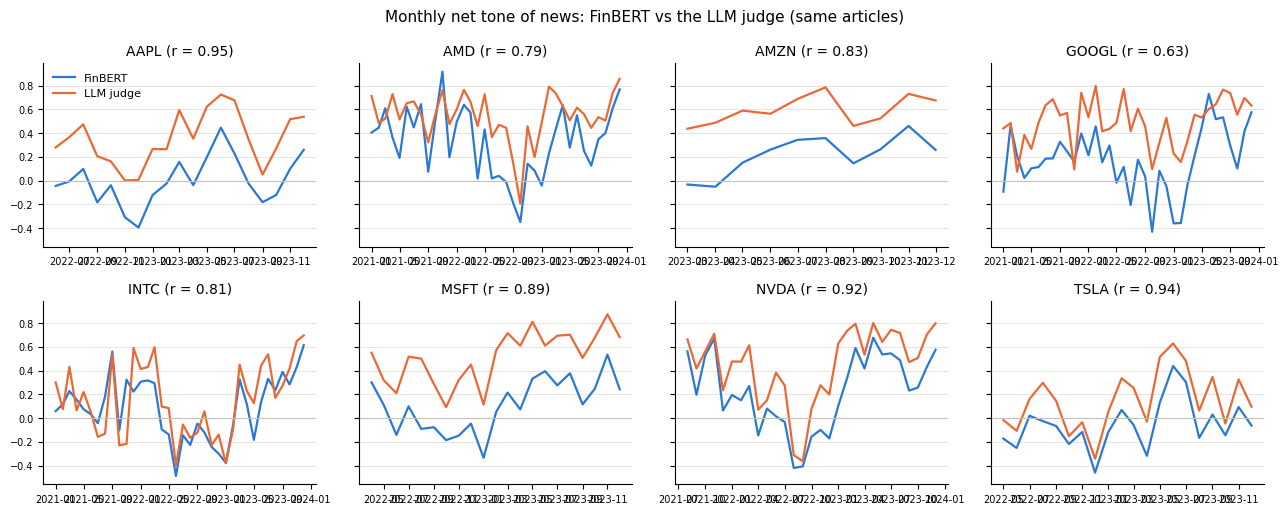

In [10]:
lab["month"] = pd.to_datetime(lab.day0).dt.to_period("M")
def tone(lbl): return ((lbl == "positive").sum() - (lbl == "negative").sum()) / ((lbl != "neutral").sum() + 1)
mc = (lab.groupby(["source", "ticker", "month"])
         .apply(lambda g: pd.Series({"n": len(g), "tone_finbert": tone(g.fin_label), "tone_judge": tone(g.judge_label)}))
         .reset_index())
mc = mc[mc.n >= np.where(mc.source == "news", 20, 10)]
mc.assign(period=mc.month.dt.start_time).drop(columns="month").to_parquet(OUT / "monthly_compare.parquet", index=False)
cor = (mc.groupby(["source", "ticker"]).apply(lambda g: pd.Series({"months": len(g),
        "corr": g.tone_finbert.corr(g.tone_judge) if len(g) >= 4 else np.nan,
        "mean_finbert": g.tone_finbert.mean(), "mean_judge": g.tone_judge.mean()})).round(3).reset_index())
print(cor.to_string(index=False)); cor.to_csv(OUT / "monthly_correlation.csv", index=False)
SUMMARY["monthly_corr"] = {f"{r.source}/{r.ticker}": r.corr for r in cor.itertuples()}
SUMMARY["monthly_corr_pooled"] = {s: round(g.tone_finbert.corr(g.tone_judge), 3) for s, g in mc.groupby("source")}

nt = sorted(mc[mc.source == "news"].ticker.unique())
if nt:
    fig, axes = plt.subplots(2, 4, figsize=(13, 5.2), sharey=True)
    for ax, t in zip(axes.ravel(), nt):
        g = mc[(mc.source == "news") & (mc.ticker == t)].sort_values("month")
        x = g.month.dt.to_timestamp()
        ax.plot(x, g.tone_finbert, color="#2a78d6", lw=1.6, label="FinBERT")
        ax.plot(x, g.tone_judge, color="#eb6834", lw=1.6, label="LLM judge")
        ax.axhline(0, color="#c3c2b7", lw=.8); ax.set_title(f"{t} (r = {g.tone_finbert.corr(g.tone_judge):.2f})", fontsize=10)
        ax.tick_params(labelsize=7); ax.grid(axis="y", color="#e1e0d9", lw=.6)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    for ax in axes.ravel()[len(nt):]: ax.axis("off")
    axes.ravel()[0].legend(fontsize=8, frameon=False)
    fig.suptitle("Monthly net tone of news: FinBERT vs the LLM judge (same articles)", fontsize=11)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "finbert_vs_judge_monthly.png", dpi=160); plt.show()

In [11]:
(OUT / "manifest_judge.json").write_text(json.dumps({"judge": JUDGE_MODEL, "labels": LABELS, "news_chars": NEWS_CHARS,
    "tweet_chars": TWEET_CHARS, "seed": SEED, "system_prompt": SYS, "n_docs": len(docs), "n_labelled": len(lab)}, indent=2))
for f in sorted(OUT.rglob("*")):
    if f.is_file(): print(f"{str(f.relative_to(OUT)):36s} {f.stat().st_size/1e6:7.2f} MB")
SUMMARY["total_minutes"] = round((time.time() - T0) / 60, 1)
print("\n" + "=" * 30 + " SUMMARY (send this back) " + "=" * 30)
print(json.dumps(SUMMARY, indent=1, default=str))

agreement.csv                           0.00 MB
confusion_news.csv                      0.00 MB
confusion_social.csv                    0.00 MB
figures/finbert_vs_judge_monthly.png    0.28 MB
finbert_tweets.parquet                  6.56 MB
llm_labels.parquet                      5.71 MB
llm_labels_partial.parquet              3.79 MB
manifest_judge.json                     0.00 MB
monthly_compare.parquet                 0.01 MB
monthly_correlation.csv                 0.00 MB

============================== SUMMARY (send this back) ==============================
{
 "judge": "Qwen/Qwen2.5-7B-Instruct",
 "n_hand_labels": 0,
 "label_minutes": 280.1,
 "docs_per_second": 6.4,
 "coverage": 1.0,
 "judge_label_share": {
  "news": {
   "negative": 0.163,
   "neutral": 0.434,
   "positive": 0.403
  },
  "social": {
   "negative": 0.205,
   "neutral": 0.341,
   "positive": 0.455
  }
 },
 "low_mass_share": 0.0001,
 "agreement": [
  {
   "subset": "news (all)",
   "n": 49993,
   "agreement": 0.569,
